In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_log_error, r2_score

In [2]:
df_train = pd.read_csv('train.csv')
df_train.head()

,id,season_code,flag_holiday,flag_working,category_weather,feature_temp,feature_feel_temp,feature_humidity,feature_wind,demand,Year,Hour,Day_of_Week,Month
0,1,4,0,1,2,0.26,0.2576,0.70,0.1642,34,2012,2,4,11
1,2,4,0,1,1,0.58,0.5455,0.64,0.0000,341,2012,11,3,10
2,3,4,0,0,3,0.22,0.1970,0.93,0.3284,67,2011,17,6,10
3,4,1,0,1,2,0.36,0.3636,0.66,0.1045,40,2011,1,3,12
4,5,1,0,0,2,0.04,0.0606,0.41,0.1642,96,2011,10,6,1


In [3]:
df_train.sample(10)

,id,season_code,flag_holiday,flag_working,category_weather,feature_temp,feature_feel_temp,feature_humidity,feature_wind,demand,Year,Hour,Day_of_Week,Month
2836,2837,4,0,1,2,0.54,0.5152,0.77,0.1045,28,2012,2,2,10
7340,7341,4,0,1,1,0.48,0.4697,0.67,0.1343,34,2012,3,3,12
11866,11867,3,0,1,1,0.60,0.5758,0.78,0.0000,28,2011,2,2,9
1535,1536,3,0,1,1,0.72,0.6515,0.30,0.0896,897,2011,14,2,8
8201,8202,1,1,0,1,0.38,0.3939,0.40,0.3284,230,2011,14,1,12
3930,3931,4,0,1,3,0.32,0.3030,0.87,0.2537,168,2012,7,2,11
3095,3096,4,0,1,2,0.54,0.5152,0.88,0.3881,566,2011,8,3,10
11799,11800,1,0,1,1,0.20,0.1818,NaN,0.3881,71,2011,6,1,3
4275,4276,2,0,0,1,0.56,0.5303,0.88,0.2537,262,2011,9,0,4
9908,9909,4,0,1,1,0.42,0.4242,0.71,0.1343,218,2011,11,3,11


In [4]:
df_train.shape

(12165, 14)

In [5]:
df_train.columns

Index(['id', 'season_code', 'flag_holiday', 'flag_working', 'category_weather',
       'feature_temp', 'feature_feel_temp', 'feature_humidity', 'feature_wind',
       'demand', 'Year', 'Hour', 'Day_of_Week', 'Month'],
      dtype='str')

In [6]:
df_train.dtypes

id                     int64
season_code            int64
flag_holiday           int64
flag_working           int64
category_weather       int64
feature_temp         float64
feature_feel_temp    float64
feature_humidity     float64
feature_wind         float64
demand                 int64
Year                   int64
Hour                   int64
Day_of_Week            int64
Month                  int64
dtype: object

In [7]:
df_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 12165 entries, 0 to 12164
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 12165 non-null  int64  
 1   season_code        12165 non-null  int64  
 2   flag_holiday       12165 non-null  int64  
 3   flag_working       12165 non-null  int64  
 4   category_weather   12165 non-null  int64  
 5   feature_temp       12165 non-null  float64
 6   feature_feel_temp  12165 non-null  float64
 7   feature_humidity   11557 non-null  float64
 8   feature_wind       11557 non-null  float64
 9   demand             12165 non-null  int64  
 10  Year               12165 non-null  int64  
 11  Hour               12165 non-null  int64  
 12  Day_of_Week        12165 non-null  int64  
 13  Month              12165 non-null  int64  
dtypes: float64(4), int64(10)
memory usage: 1.3 MB


In [8]:
df_train.describe()

,id,season_code,flag_holiday,flag_working,category_weather,feature_temp,feature_feel_temp,feature_humidity,feature_wind,demand,Year,Hour,Day_of_Week,Month
count,12165.000000,12165.000000,12165.000000,12165.000000,12165.000000,12165.000000,12165.000000,11557.000000,11557.000000,12165.000000,12165.000000,12165.000000,12165.000000,12165.000000
mean,6083.000000,2.500534,0.028442,0.685656,1.425072,0.497197,0.475919,0.626863,0.189611,279.223263,2011.501192,11.573120,3.002466,6.541060
std,3511.877347,1.109777,0.166239,0.464273,0.637076,0.192414,0.171508,0.193058,0.121757,241.989716,0.500019,6.907753,2.000697,3.439269
min,1.000000,1.000000,0.000000,0.000000,1.000000,0.020000,0.015200,0.000000,0.000000,26.000000,2011.000000,0.000000,0.000000,1.000000
25%,3042.000000,2.000000,0.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,79.000000,2011.000000,6.000000,1.000000,4.000000
50%,6083.000000,3.000000,0.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,218.000000,2012.000000,12.000000,3.000000,7.000000
75%,9124.000000,3.000000,0.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,402.000000,2012.000000,18.000000,5.000000,10.000000
max,12165.000000,4.000000,1.000000,1.000000,4.000000,0.980000,1.000000,1.000000,0.850700,1334.000000,2012.000000,23.000000,6.000000,12.000000


In [9]:
df_train.isnull().sum()

id                     0
season_code            0
flag_holiday           0
flag_working           0
category_weather       0
feature_temp           0
feature_feel_temp      0
feature_humidity     608
feature_wind         608
demand                 0
Year                   0
Hour                   0
Day_of_Week            0
Month                  0
dtype: int64

In [10]:
df_train.duplicated().sum()

np.int64(0)

In [11]:
df_train.nunique()

id                   12165
season_code              4
flag_holiday             2
flag_working             2
category_weather         4
feature_temp            49
feature_feel_temp       64
feature_humidity        87
feature_wind            29
demand                 830
Year                     2
Hour                    24
Day_of_Week              7
Month                   12
dtype: int64

In [12]:
df_test = pd.read_csv("test.csv")
df_test.head()

,id,season_code,flag_holiday,flag_working,category_weather,feature_temp,feature_feel_temp,feature_humidity,feature_wind,Year,Hour,Day_of_Week,Month
0,12166,3,0,1,2,0.62,0.5909,0.78,0.1642,2011,6,1,6
1,12167,2,0,1,1,0.70,0.6667,0.79,NaN,2012,0,2,5
2,12168,4,0,1,1,0.32,0.3030,0.45,0.2537,2011,14,4,12
3,12169,1,1,0,2,0.16,0.1515,0.55,0.1940,2011,11,1,1
4,12170,1,0,1,1,0.52,0.5000,0.63,0.0896,2012,1,3,3


In [13]:
df_test.info()

<class 'pandas.DataFrame'>
RangeIndex: 5214 entries, 0 to 5213
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5214 non-null   int64  
 1   season_code        5214 non-null   int64  
 2   flag_holiday       5214 non-null   int64  
 3   flag_working       5214 non-null   int64  
 4   category_weather   5214 non-null   int64  
 5   feature_temp       5214 non-null   float64
 6   feature_feel_temp  5214 non-null   float64
 7   feature_humidity   4953 non-null   float64
 8   feature_wind       4953 non-null   float64
 9   Year               5214 non-null   int64  
 10  Hour               5214 non-null   int64  
 11  Day_of_Week        5214 non-null   int64  
 12  Month              5214 non-null   int64  
dtypes: float64(4), int64(9)
memory usage: 529.7 KB


In [14]:
df_test.isnull().sum()

id                     0
season_code            0
flag_holiday           0
flag_working           0
category_weather       0
feature_temp           0
feature_feel_temp      0
feature_humidity     261
feature_wind         261
Year                   0
Hour                   0
Day_of_Week            0
Month                  0
dtype: int64

In [15]:
dependence = ['season_code', 'category_weather']
medians = df_train.groupby(dependence)[['feature_wind', 'feature_humidity']].transform('median')
df_train = df_train.combine_first(medians)

reference = df_train.groupby(dependence)[['feature_wind', 'feature_humidity']].median()
df_test = df_test.set_index(dependence).combine_first(reference).reset_index()

global_medians = df_train[['feature_wind', 'feature_humidity']].median()
df_train = df_train.fillna(global_medians)
df_test = df_test.fillna(global_medians)

In [16]:
df_train.isnull().sum()

id                   0
season_code          0
flag_holiday         0
flag_working         0
category_weather     0
feature_temp         0
feature_feel_temp    0
feature_humidity     0
feature_wind         0
demand               0
Year                 0
Hour                 0
Day_of_Week          0
Month                0
dtype: int64

In [17]:
df_test.isnull().sum()

season_code          0
category_weather     0
id                   0
flag_holiday         0
flag_working         0
feature_temp         0
feature_feel_temp    0
feature_humidity     0
feature_wind         0
Year                 0
Hour                 0
Day_of_Week          0
Month                0
dtype: int64

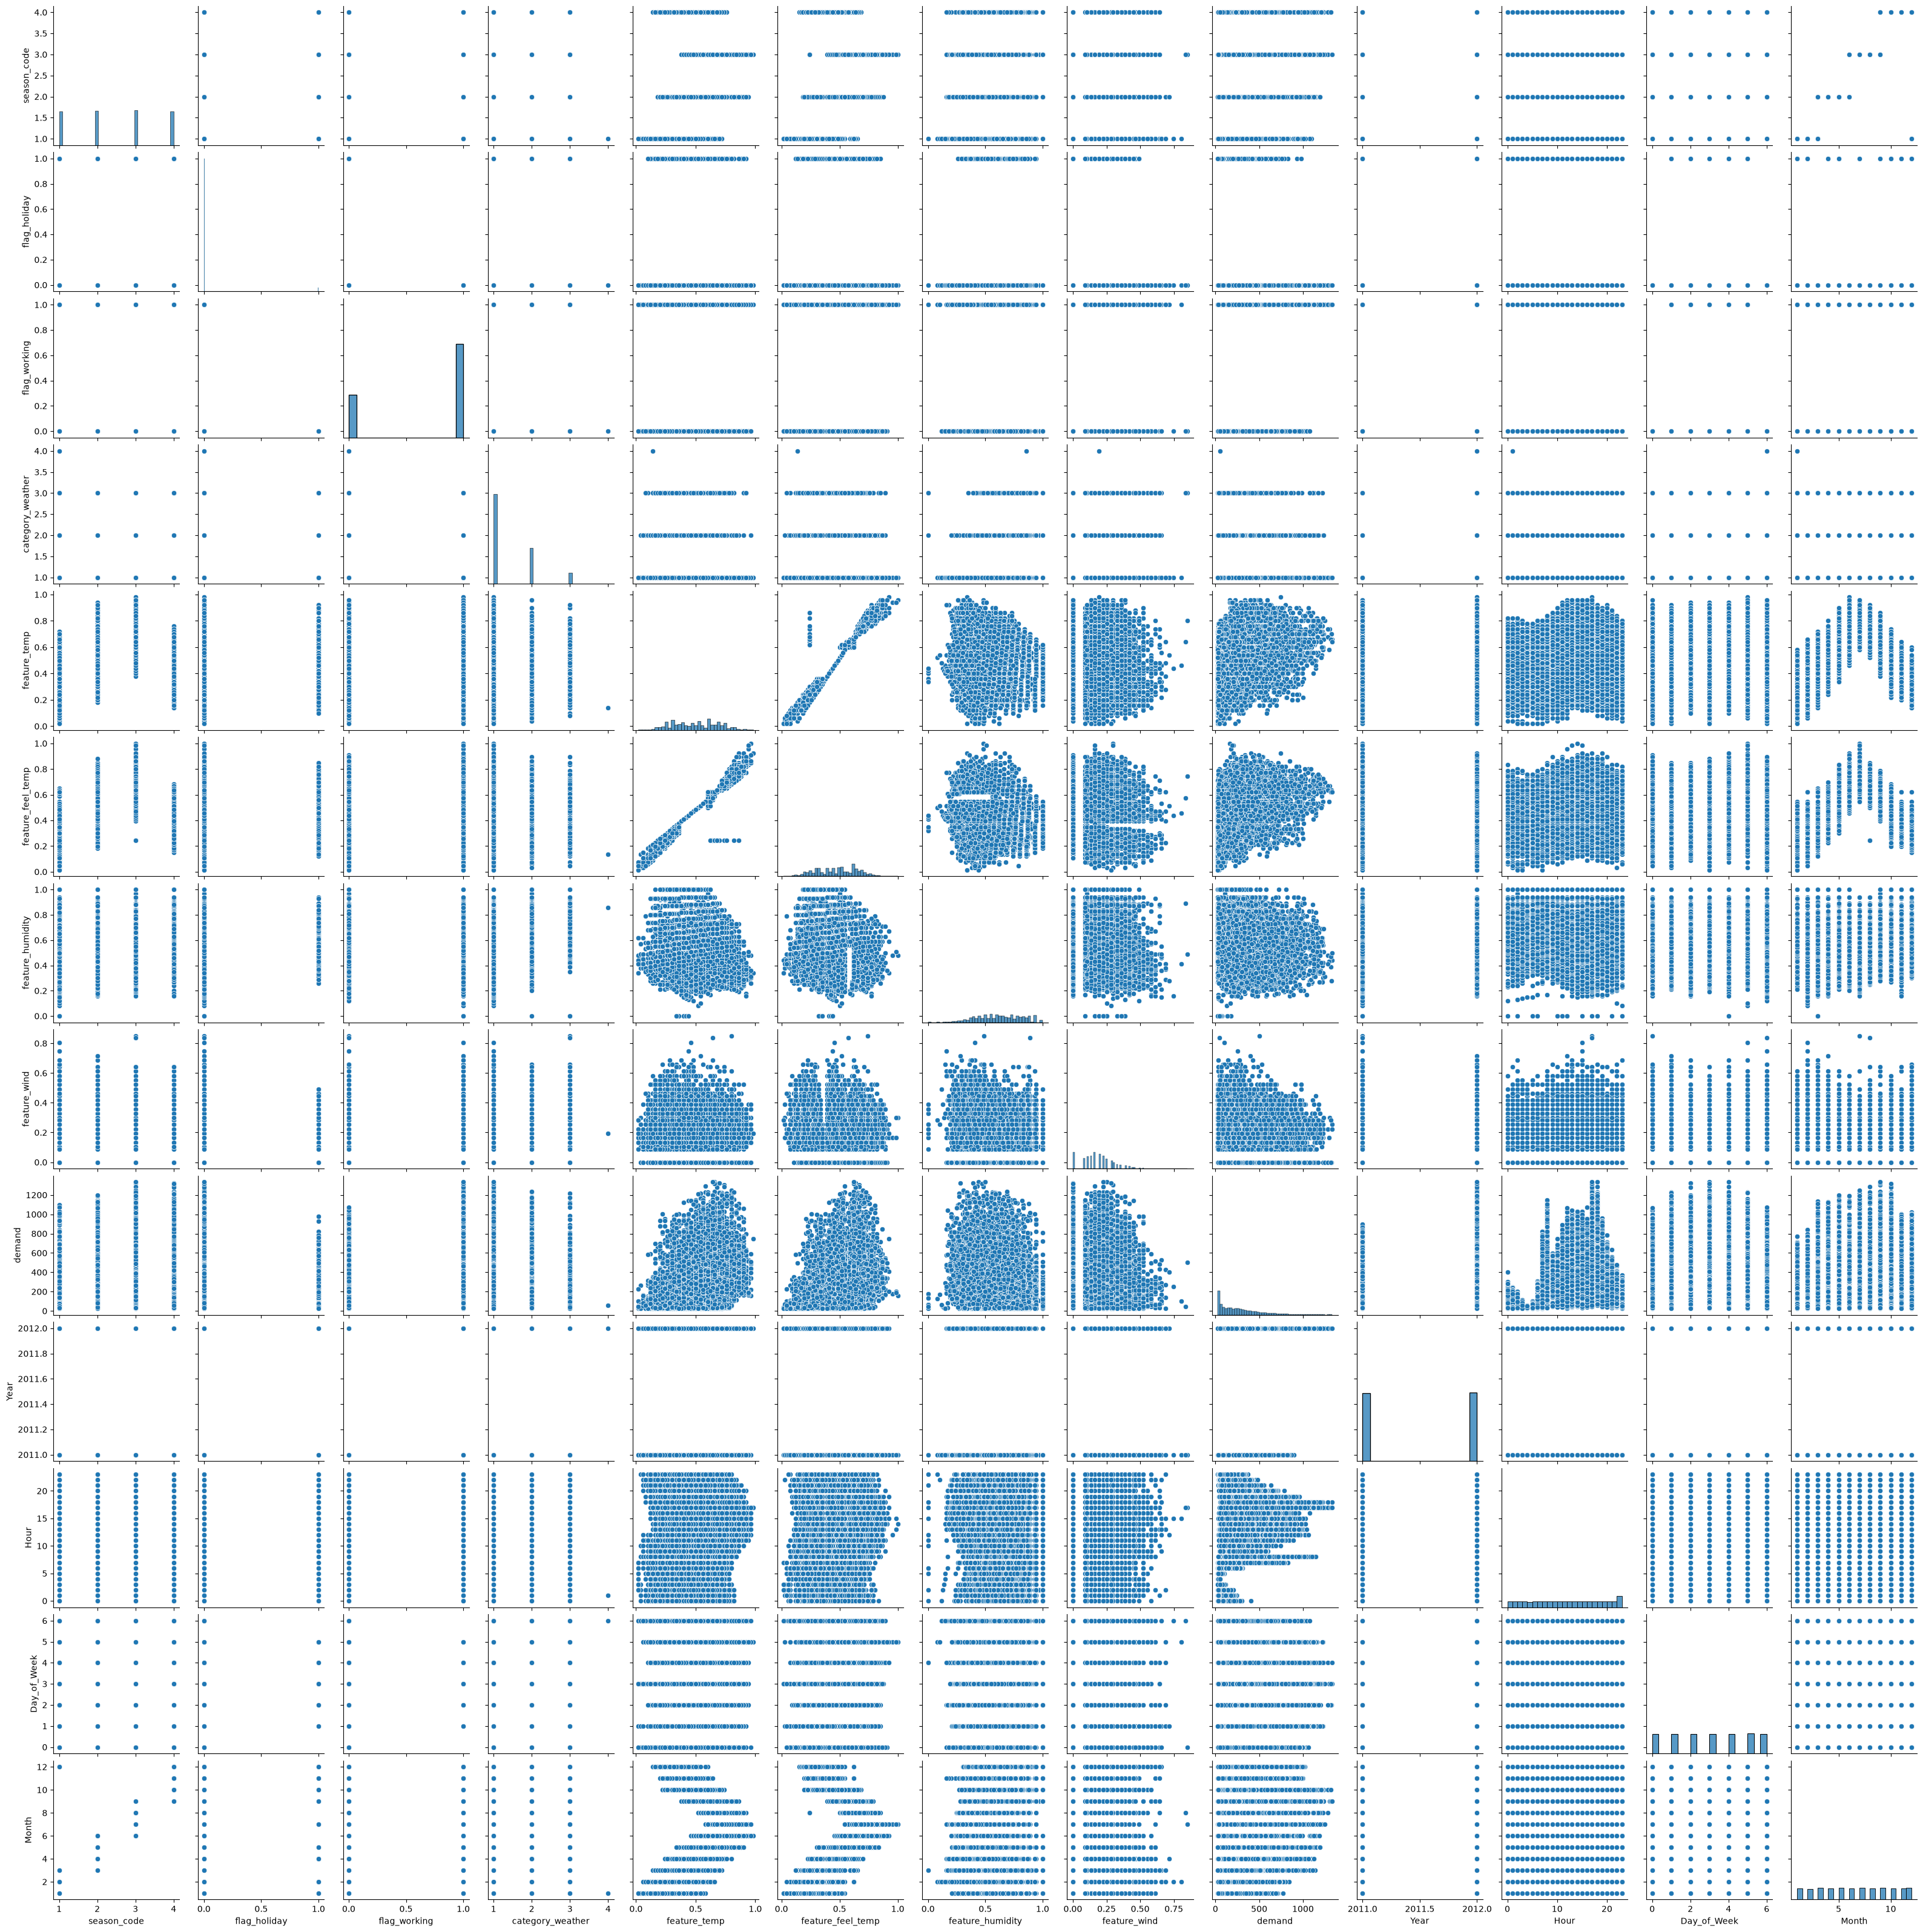

In [18]:
sns.pairplot(df_train.drop(columns = 'id'))

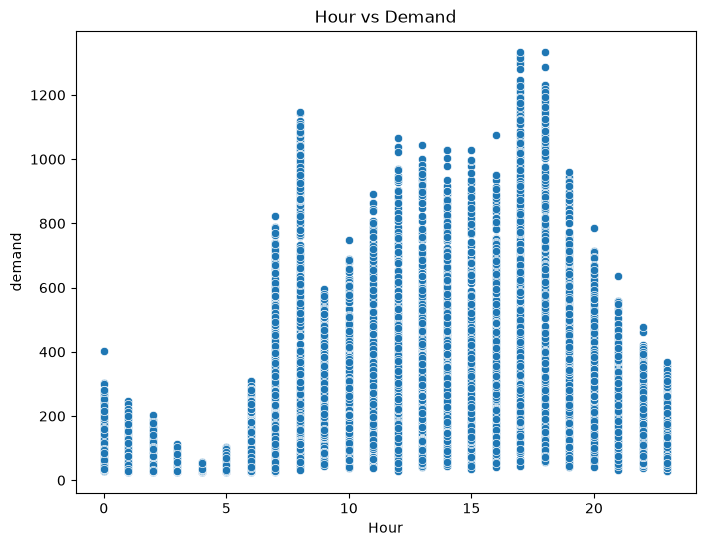

In [19]:
plt.figure(figsize=(8,6))
sns.scatterplot(x='Hour',y='demand',data=df_train)
plt.title("Hour vs Demand")
plt.show()

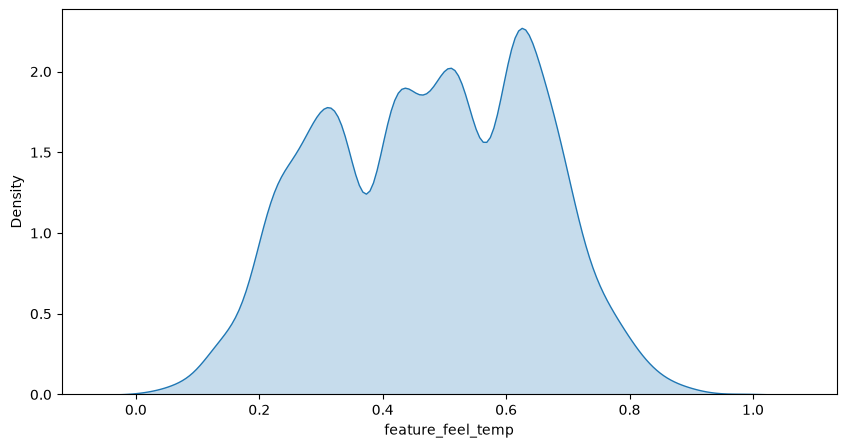

In [20]:
plt.figure(figsize=(10,5))
sns.kdeplot(df_train['feature_feel_temp'],fill=True)
plt.show()

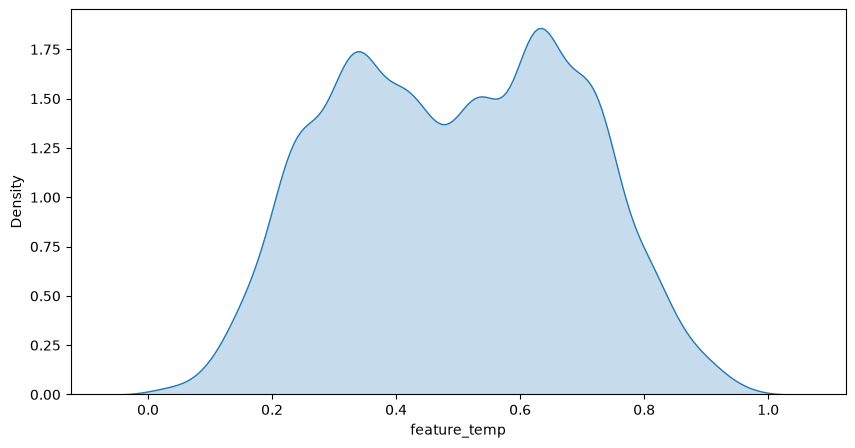

In [21]:
plt.figure(figsize=(10,5))
sns.kdeplot(df_train['feature_temp'],fill=True)
plt.show()

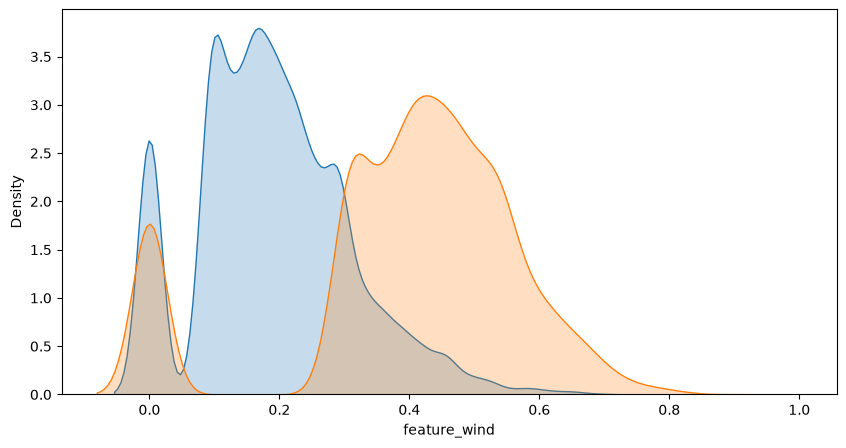

In [22]:
plt.figure(figsize=(10,5))
sns.kdeplot(df_train['feature_wind'],fill=True)
sns.kdeplot(np.sqrt(df_train['feature_wind']),fill=True)

plt.show()

In [23]:
df_train['feature_wind'] = np.sqrt(df_train['feature_wind'])
df_test['feature_wind'] = np.sqrt(df_test['feature_wind'])

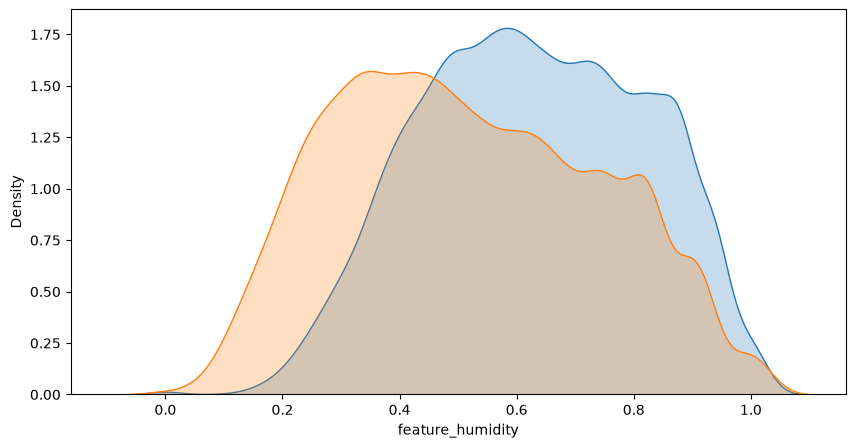

In [24]:
plt.figure(figsize=(10,5))
sns.kdeplot(df_train['feature_humidity'],fill=True)
sns.kdeplot(np.power(df_train['feature_humidity'], 1.5),fill=True)
plt.show()

In [25]:
df_train['feature_humidity'] = np.power(df_train['feature_humidity'], 1.5)
df_test['feature_humidity'] = np.power(df_test['feature_humidity'], 1.5)

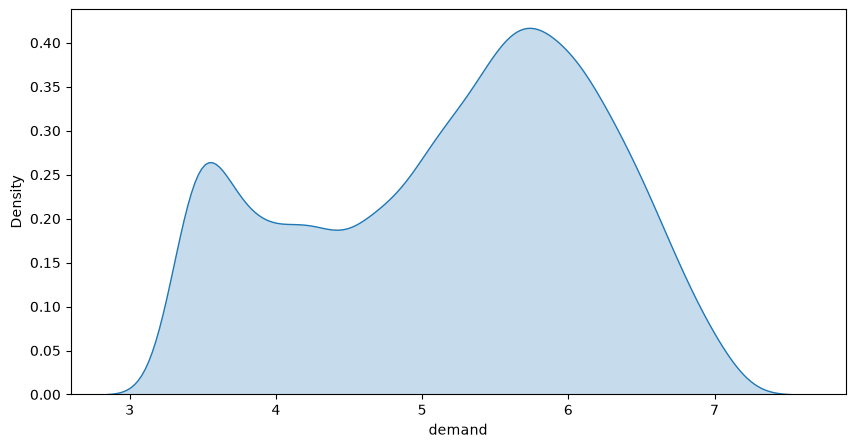

In [26]:
plt.figure(figsize=(10,5))
sns.kdeplot(np.log1p(df_train['demand']),fill=True)

plt.show()

In [27]:
ohe_cols = ['season_code', 'category_weather', 'Day_of_Week', 'Hour', 'Year', 'Month']

for col in ohe_cols:
    if col in df_train.columns:
        df_train[col] = df_train[col].astype(str)
        df_test[col] = df_test[col].astype(str)

df_train = pd.get_dummies(df_train, columns=ohe_cols, drop_first=True, dtype=int)
df_test = pd.get_dummies(df_test, columns=ohe_cols, drop_first=True, dtype=int)

new_order = [col for col in df_train.columns if col != 'demand'] + ['demand']
df_train = df_train[new_order]

In [28]:
df_train.columns

Index(['id', 'flag_holiday', 'flag_working', 'feature_temp',
       'feature_feel_temp', 'feature_humidity', 'feature_wind',
       'season_code_2', 'season_code_3', 'season_code_4', 'category_weather_2',
       'category_weather_3', 'category_weather_4', 'Day_of_Week_1',
       'Day_of_Week_2', 'Day_of_Week_3', 'Day_of_Week_4', 'Day_of_Week_5',
       'Day_of_Week_6', 'Hour_1', 'Hour_10', 'Hour_11', 'Hour_12', 'Hour_13',
       'Hour_14', 'Hour_15', 'Hour_16', 'Hour_17', 'Hour_18', 'Hour_19',
       'Hour_2', 'Hour_20', 'Hour_21', 'Hour_22', 'Hour_23', 'Hour_3',
       'Hour_4', 'Hour_5', 'Hour_6', 'Hour_7', 'Hour_8', 'Hour_9', 'Year_2012',
       'Month_10', 'Month_11', 'Month_12', 'Month_2', 'Month_3', 'Month_4',
       'Month_5', 'Month_6', 'Month_7', 'Month_8', 'Month_9', 'demand'],
      dtype='str')

In [29]:
df_train.head()

,id,flag_holiday,flag_working,feature_temp,feature_feel_temp,feature_humidity,feature_wind,season_code_2,season_code_3,season_code_4,...,Month_12,Month_2,Month_3,Month_4,Month_5,Month_6,Month_7,Month_8,Month_9,demand
0,1,0,1,0.26,0.2576,0.585662,0.405216,0,0,1,...,0,0,0,0,0,0,0,0,0,34
1,2,0,1,0.58,0.5455,0.512000,0.000000,0,0,1,...,0,0,0,0,0,0,0,0,0,341
2,3,0,0,0.22,0.1970,0.896860,0.573062,0,0,1,...,0,0,0,0,0,0,0,0,0,67
3,4,0,1,0.36,0.3636,0.536187,0.323265,0,0,0,...,1,0,0,0,0,0,0,0,0,40
4,5,0,0,0.04,0.0606,0.262528,0.405216,0,0,0,...,0,0,0,0,0,0,0,0,0,96


In [30]:
df_test.head()

,id,flag_holiday,flag_working,feature_temp,feature_feel_temp,feature_humidity,feature_wind,season_code_2,season_code_3,season_code_4,...,Month_11,Month_12,Month_2,Month_3,Month_4,Month_5,Month_6,Month_7,Month_8,Month_9
0,12170,0,1,0.52,0.5000,0.500047,0.299333,0,0,0,...,0,0,0,1,0,0,0,0,0,0
1,12175,0,1,0.22,0.2727,0.512000,0.000000,0,0,0,...,0,0,1,0,0,0,0,0,0,0
2,12178,0,0,0.44,0.4394,0.291863,0.440454,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,12183,1,0,0.34,0.2879,0.272191,0.722772,0,0,0,...,0,1,0,0,0,0,0,0,0,0
4,12187,0,1,0.24,0.2273,0.585662,0.503686,0,0,0,...,0,0,1,0,0,0,0,0,0,0


In [31]:
numeric_df = df_train.select_dtypes(include=np.number)
corr = numeric_df.corr()
corr

,id,flag_holiday,flag_working,feature_temp,feature_feel_temp,feature_humidity,feature_wind,season_code_2,season_code_3,season_code_4,...,Month_12,Month_2,Month_3,Month_4,Month_5,Month_6,Month_7,Month_8,Month_9,demand
id,1.000000,0.002397,-0.001561,0.004624,0.005742,-0.007557,-0.001285,0.013184,0.009003,-0.019693,...,-0.016386,-0.006629,0.011537,0.010918,0.004162,-0.004550,0.000748,0.014379,-0.003216,-0.003947
flag_holiday,0.002397,1.000000,-0.252696,-0.032358,-0.035302,-0.010322,-0.004081,-0.025230,-0.024944,0.010763,...,0.013629,0.003271,-0.052148,0.006840,0.006474,-0.051317,0.003864,-0.051623,0.009695,-0.036413
flag_working,-0.001561,-0.252696,1.000000,0.048867,0.047249,0.017249,-0.011838,0.014338,0.015476,-0.005977,...,-0.012658,0.003833,0.027322,-0.015638,0.003434,0.023552,-0.016134,0.042937,-0.010591,0.024296
feature_temp,0.004624,-0.032358,0.048867,1.000000,0.988547,-0.064564,-0.008644,0.146382,0.641806,-0.214336,...,-0.271841,-0.295453,-0.170727,-0.041338,0.155346,0.292721,0.412641,0.333158,0.188394,0.400890
feature_feel_temp,0.005742,-0.035302,0.047249,0.988547,1.000000,-0.049806,-0.046653,0.153379,0.620193,-0.195502,...,-0.264378,-0.294119,-0.169479,-0.032294,0.159633,0.285042,0.408826,0.311798,0.182142,0.397118
feature_humidity,-0.007557,-0.010322,0.017249,-0.064564,-0.049806,1.000000,-0.219311,0.009673,0.007804,0.122503,...,0.060133,-0.098238,-0.048544,-0.048088,0.094585,-0.074406,-0.053858,0.006305,0.137208,-0.318492
feature_wind,-0.001285,-0.004081,-0.011838,-0.008644,-0.046653,-0.219311,1.000000,0.076550,-0.074642,-0.094815,...,-0.030131,0.041235,0.070899,0.085394,0.006605,0.006676,-0.047432,-0.050026,-0.044490,0.088908
season_code_2,0.013184,-0.025230,0.014338,0.146382,0.153379,0.009673,0.076550,1.000000,-0.341587,-0.330204,...,-0.176565,-0.169548,0.068968,0.513536,0.524728,0.292563,-0.178150,-0.175063,-0.177219,0.049362
season_code_3,0.009003,-0.024944,0.015476,0.641806,0.620193,0.007804,-0.074642,-0.341587,1.000000,-0.335030,...,-0.179145,-0.172026,-0.179430,-0.175417,-0.179240,0.046186,0.521537,0.512500,0.319589,0.156889
season_code_4,-0.019693,0.010763,-0.005977,-0.214336,-0.195502,0.122503,-0.094815,-0.330204,-0.335030,1.000000,...,0.277924,-0.166293,-0.173450,-0.169572,-0.173267,-0.170686,-0.174731,-0.171703,0.028795,0.033262


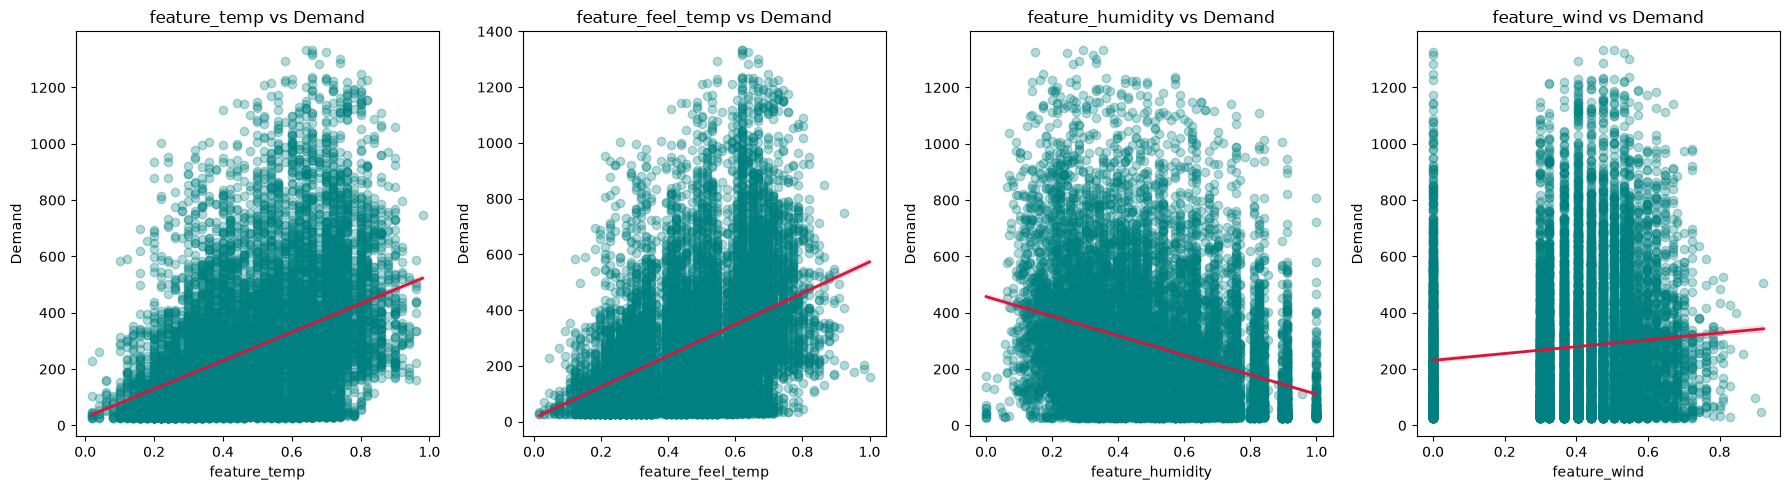

In [32]:
features = ["feature_temp", "feature_feel_temp", "feature_humidity", "feature_wind"]

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

for i, col in enumerate(features):
    sns.regplot(
        data=df_train,
        x=col,
        y="demand",
        ax=axes[i],
        scatter_kws={"alpha": 0.3, "color": "teal"},
        line_kws={"color": "crimson", "linewidth": 2},
    )
    axes[i].set_title(f"{col} vs Demand")
    axes[i].set_ylabel("Demand")
    axes[i].set_xlabel(col)

plt.tight_layout()
plt.show()

In [33]:
df_train = df_train.drop(columns = 'feature_temp')
df_test = df_test.drop(columns = 'feature_temp')

In [34]:
df_train['Hour_8_Workday'] = df_train['Hour_8'] * df_train['flag_working']
df_train['Hour_17_Workday'] = df_train['Hour_17'] * df_train['flag_working']
df_train['Hour_18_Workday'] = df_train['Hour_18'] * df_train['flag_working']

df_test['Hour_8_Workday'] = df_test['Hour_8'] * df_test['flag_working']
df_test['Hour_17_Workday'] = df_test['Hour_17'] * df_test['flag_working']
df_test['Hour_18_Workday'] = df_test['Hour_18'] * df_test['flag_working']

In [35]:
# df_train['wind_workday'] = df_train['feature_wind'] * df_train['flag_working']
# df_test['wind_workday'] = df_test['feature_wind'] * df_test['flag_working']

# df_train['humidity_workday'] = df_train['feature_humidity'] * df_train['flag_working']
# df_test['humidity_workday'] = df_test['feature_humidity'] * df_test['flag_working']

In [36]:
df_train.columns

Index(['id', 'flag_holiday', 'flag_working', 'feature_feel_temp',
       'feature_humidity', 'feature_wind', 'season_code_2', 'season_code_3',
       'season_code_4', 'category_weather_2', 'category_weather_3',
       'category_weather_4', 'Day_of_Week_1', 'Day_of_Week_2', 'Day_of_Week_3',
       'Day_of_Week_4', 'Day_of_Week_5', 'Day_of_Week_6', 'Hour_1', 'Hour_10',
       'Hour_11', 'Hour_12', 'Hour_13', 'Hour_14', 'Hour_15', 'Hour_16',
       'Hour_17', 'Hour_18', 'Hour_19', 'Hour_2', 'Hour_20', 'Hour_21',
       'Hour_22', 'Hour_23', 'Hour_3', 'Hour_4', 'Hour_5', 'Hour_6', 'Hour_7',
       'Hour_8', 'Hour_9', 'Year_2012', 'Month_10', 'Month_11', 'Month_12',
       'Month_2', 'Month_3', 'Month_4', 'Month_5', 'Month_6', 'Month_7',
       'Month_8', 'Month_9', 'demand', 'Hour_8_Workday', 'Hour_17_Workday',
       'Hour_18_Workday'],
      dtype='str')

In [37]:
df_train['feature_feel_temp_sq'] = df_train['feature_feel_temp'] ** 2
df_test['feature_feel_temp_sq'] = df_test['feature_feel_temp'] ** 2

In [38]:
df_train.head()

,id,flag_holiday,flag_working,feature_feel_temp,feature_humidity,feature_wind,season_code_2,season_code_3,season_code_4,category_weather_2,...,Month_5,Month_6,Month_7,Month_8,Month_9,demand,Hour_8_Workday,Hour_17_Workday,Hour_18_Workday,feature_feel_temp_sq
0,1,0,1,0.2576,0.585662,0.405216,0,0,1,1,...,0,0,0,0,0,34,0,0,0,0.066358
1,2,0,1,0.5455,0.512000,0.000000,0,0,1,0,...,0,0,0,0,0,341,0,0,0,0.297570
2,3,0,0,0.1970,0.896860,0.573062,0,0,1,0,...,0,0,0,0,0,67,0,0,0,0.038809
3,4,0,1,0.3636,0.536187,0.323265,0,0,0,1,...,0,0,0,0,0,40,0,0,0,0.132205
4,5,0,0,0.0606,0.262528,0.405216,0,0,0,1,...,0,0,0,0,0,96,0,0,0,0.003672


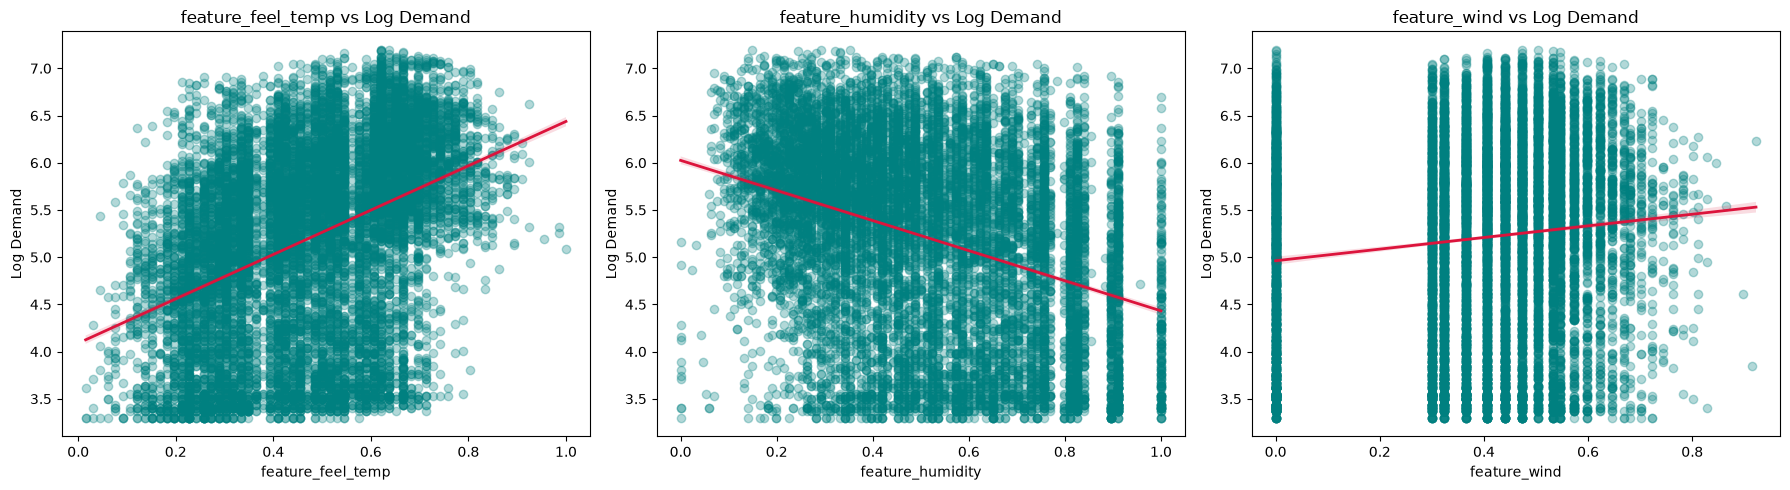

In [39]:
features = ["feature_feel_temp", "feature_humidity", "feature_wind"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(features):
    sns.regplot(
        data=df_train,
        x=col,
        y=np.log1p(df_train["demand"]),
        ax=axes[i],
        scatter_kws={"alpha": 0.3, "color": "teal"},
        line_kws={"color": "crimson", "linewidth": 2},
    )
    axes[i].set_title(f"{col} vs Log Demand")
    axes[i].set_ylabel("Log Demand")
    axes[i].set_xlabel(col)

plt.tight_layout()
plt.show()

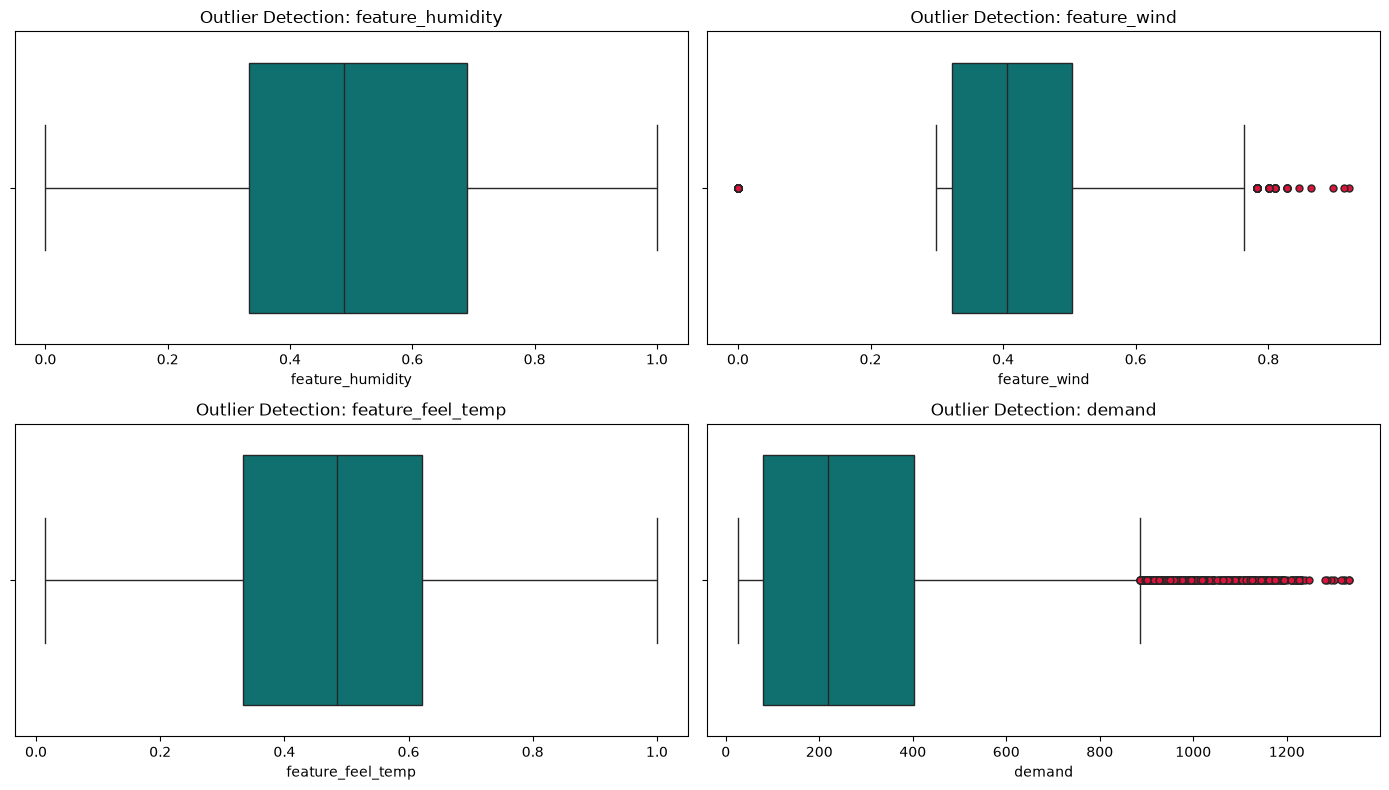

In [40]:
import math
outlier_check_cols = [
    "feature_humidity",
    "feature_wind",
    "feature_feel_temp",
    "demand",
]

num_features = len(outlier_check_cols)
num_cols = 2
num_rows = math.ceil(num_features / num_cols)

fig, axes = plt.subplots(num_rows, num_cols, figsize=(14, 4 * num_rows))
axes = axes.flatten()

for i, col in enumerate(outlier_check_cols):
    if col in df_train.columns:
        sns.boxplot(
            data=df_train,
            x=col,
            ax=axes[i],
            color="teal",
            flierprops={
                "markerfacecolor": "crimson",
                "marker": "o",
                "markersize": 5,
            },
        )
        axes[i].set_title(f"Outlier Detection: {col}")
        axes[i].set_xlabel(col)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [41]:
lower_wind_bound = 0.15
higher_wind_bound = 0.75

df_train["feature_wind"] = df_train["feature_wind"].clip(
    lower = lower_wind_bound,
    upper = higher_wind_bound
)
df_test["feature_wind"] = df_test["feature_wind"].clip(
    lower = lower_wind_bound,
    upper = higher_wind_bound
)

<Axes: xlabel='feature_wind'>

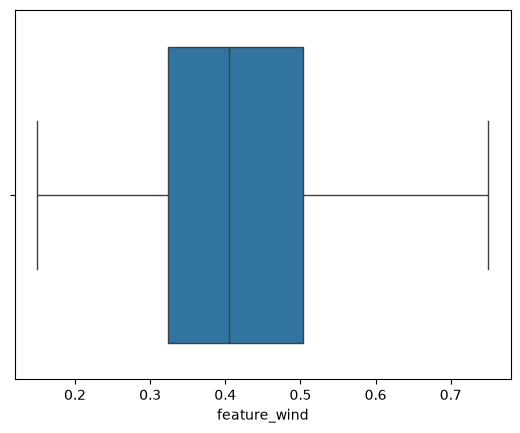

In [42]:
sns.boxplot(x='feature_wind', data=df_train)

In [43]:
X = df_train.drop(columns=['id', 'demand'])
y = df_train['demand']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [44]:
y_train_log = np.log1p(y_train)

<Axes: xlabel='demand'>

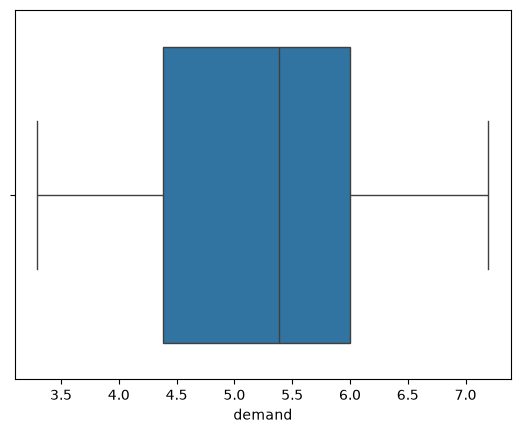

In [45]:
sns.boxplot(x=y_train_log, data=df_train)

In [46]:
reg = Ridge(alpha=0.01)
reg.fit(X_train, y_train_log)

,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",0.01
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga'

In [47]:
y_pred_log = reg.predict(X_test)

y_pred = np.expm1(y_pred_log)

In [48]:
r2_score(y_test, y_pred)

0.805356665090442

In [49]:
root_mean_squared_log_error(y_test, y_pred)

0.3970086006713456

In [50]:
y_full_raw = df_train['demand']
y_full_log = np.log1p(y_full_raw)

X_full = X  

model = Ridge(alpha=0.01)

In [51]:
X_full.shape

(12165, 56)

In [52]:
y_full_log.shape

(12165,)

In [53]:
model.fit(X_full, y_full_log)

,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",0.01
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga'

In [54]:
df_test_fresh = pd.read_csv('test.csv')

df_test_aligned = df_test.set_index('id').reindex(df_test_fresh['id']).reset_index()

X_test_final = df_test_aligned.drop(columns=['id', 'demand', 'feature_temp'], errors='ignore')

X_test_final = X_test_final.reindex(columns=X_full.columns, fill_value=0)

final_preds_log = model.predict(X_test_final)

final_preds_raw = np.expm1(final_preds_log)

final_preds_clean = np.clip(final_preds_raw, 0, None)

submission = pd.DataFrame({
    'id': df_test_fresh['id'].astype(int),
    'demand': final_preds_clean
})

submission.to_csv('submission.csv', index=False)

submission.head()

,id,demand
0,12166,111.439081
1,12167,131.157316
2,12168,218.157927
3,12169,93.253755
4,12170,66.494086


In [55]:
X_test_final.head()

,flag_holiday,flag_working,feature_feel_temp,feature_humidity,feature_wind,season_code_2,season_code_3,season_code_4,category_weather_2,category_weather_3,...,Month_4,Month_5,Month_6,Month_7,Month_8,Month_9,Hour_8_Workday,Hour_17_Workday,Hour_18_Workday,feature_feel_temp_sq
0,0,1,0.5909,0.688877,0.405216,0,1,0,1,0,...,0,0,1,0,0,0,0,0,0,0.349163
1,0,1,0.6667,0.702167,0.440454,1,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0.444489
2,0,1,0.3030,0.301869,0.503686,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0.091809
3,1,0,0.1515,0.407891,0.440454,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0.022952
4,0,1,0.5000,0.500047,0.299333,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0.250000


In [56]:
X_test_final.columns

Index(['flag_holiday', 'flag_working', 'feature_feel_temp', 'feature_humidity',
       'feature_wind', 'season_code_2', 'season_code_3', 'season_code_4',
       'category_weather_2', 'category_weather_3', 'category_weather_4',
       'Day_of_Week_1', 'Day_of_Week_2', 'Day_of_Week_3', 'Day_of_Week_4',
       'Day_of_Week_5', 'Day_of_Week_6', 'Hour_1', 'Hour_10', 'Hour_11',
       'Hour_12', 'Hour_13', 'Hour_14', 'Hour_15', 'Hour_16', 'Hour_17',
       'Hour_18', 'Hour_19', 'Hour_2', 'Hour_20', 'Hour_21', 'Hour_22',
       'Hour_23', 'Hour_3', 'Hour_4', 'Hour_5', 'Hour_6', 'Hour_7', 'Hour_8',
       'Hour_9', 'Year_2012', 'Month_10', 'Month_11', 'Month_12', 'Month_2',
       'Month_3', 'Month_4', 'Month_5', 'Month_6', 'Month_7', 'Month_8',
       'Month_9', 'Hour_8_Workday', 'Hour_17_Workday', 'Hour_18_Workday',
       'feature_feel_temp_sq'],
      dtype='str')